# Box Plot Practical (ABA Unit 1, Practical 6)

**Aim:** create box plots to analyse distribution characteristics and find outliers (Sahyadri Mart daily sales, synthetic).

Run the cells in order (Runtime → Run all). Nothing to install. The note `box-plot-practical` on Sutra explains every step.

In [1]:
# Step 1. Load the data, pick S05 (the Pune Express store) and set a clean chart style
import pandas as pd
import matplotlib.pyplot as plt

url = ("https://raw.githubusercontent.com/Prathameshv07/ai-ds-notes/main/"
       "content/assets/data/sahyadri-mart-sales.csv")
df = pd.read_csv(url, parse_dates=["date"])
s05 = df[df["store_id"] == "S05"]
f = s05["footfall"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
BOX = dict(patch_artist=True, boxprops=dict(facecolor="#cfe2f8", edgecolor="#257de0"),
           medianprops=dict(color="#f47230", linewidth=2),
           flierprops=dict(marker="o", markersize=5, markerfacecolor="#257de0", markeredgecolor="white"))
print("Days for S05:", len(f))

Days for S05: 731


In [2]:
# Step 2. The numbers behind the box: five-number summary, IQR and fences
q1, median, q3 = f.quantile([0.25, 0.50, 0.75])
iqr = q3 - q1
low_fence, high_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
inside = f[(f >= low_fence) & (f <= high_fence)]
print(f"Minimum      : {f.min()}")
print(f"Q1           : {q1:.0f}")
print(f"Median (Q2)  : {median:.0f}")
print(f"Q3           : {q3:.0f}")
print(f"Maximum      : {f.max()}")
print(f"IQR = Q3 - Q1: {iqr:.0f}")
print(f"Fences       : {low_fence:.0f} to {high_fence:.0f}")
print(f"Whiskers end : {inside.min()} and {inside.max()}  (furthest days inside the fences)")
print(f"Outliers     : {(f < low_fence).sum()} low, {(f > high_fence).sum()} high")

Minimum      : 721
Q1           : 1077
Median (Q2)  : 1227
Q3           : 1393
Maximum      : 2486
IQR = Q3 - Q1: 316
Fences       : 603 to 1867
Whiskers end : 721 and 1849  (furthest days inside the fences)
Outliers     : 0 low, 15 high


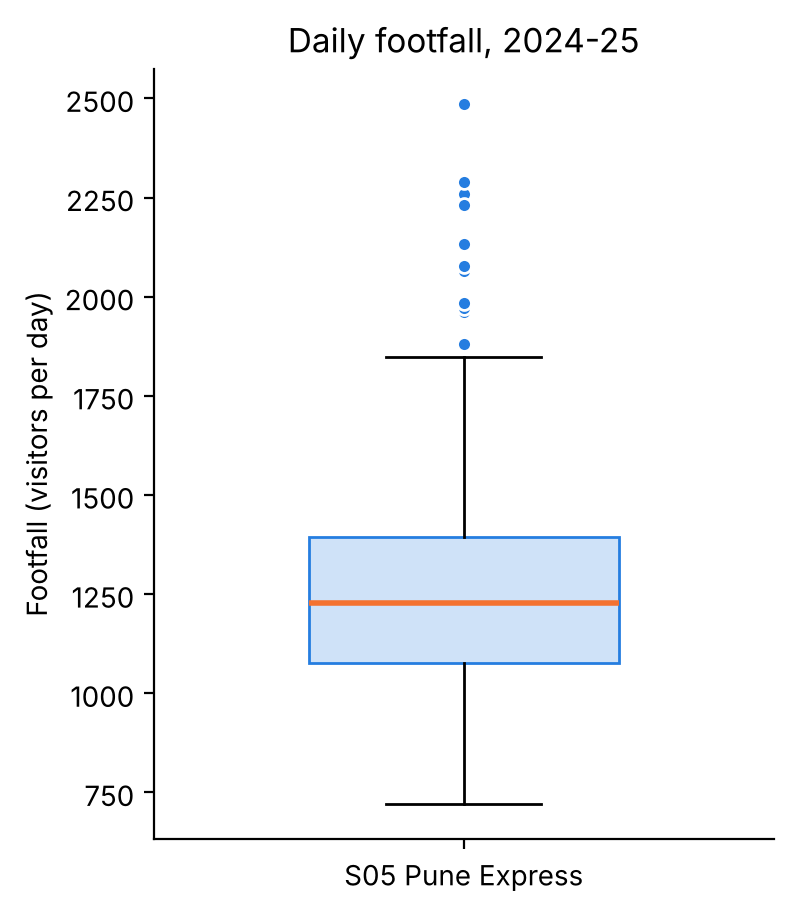

In [3]:
# Step 3. Draw the box plot of S05's daily footfall
plt.figure(figsize=(4, 5))
plt.boxplot(f, widths=0.5, **BOX)
plt.xticks([1], ["S05 Pune Express"])
plt.ylabel("Footfall (visitors per day)")
plt.title("Daily footfall, 2024-25")
plt.show()

In [4]:
# Step 4. Who are the outliers? List the high-outlier days
out = s05[f > high_fence]
print(out[["date", "day_of_week", "is_festival", "discount_pct", "footfall"]]
      .sort_values("footfall", ascending=False).to_string(index=False))
print("\nFestival days:", out["is_festival"].sum(), "| Saturdays or Sundays:",
      out["day_of_week"].isin(["Saturday", "Sunday"]).sum(), "| of", len(out))

      date day_of_week  is_festival  discount_pct  footfall
2025-10-21     Tuesday            1            10      2486
2025-10-19      Sunday            1            10      2290
2024-09-07    Saturday            1            10      2259
2024-10-31    Thursday            1            10      2230
2025-03-30      Sunday            1            10      2132
2025-12-21      Sunday            0            15      2077
2024-11-01      Friday            1            10      2064
2025-12-28      Sunday            0            10      1983
2025-10-18    Saturday            1            10      1971
2024-12-22      Sunday            0            10      1961
2024-12-08      Sunday            0             5      1889
2025-10-11    Saturday            0             5      1884
2025-10-20      Monday            1            10      1881
2024-10-12    Saturday            1            10      1880
2024-04-07      Sunday            1            10      1879

Festival days: 10 | Saturdays or Sunday

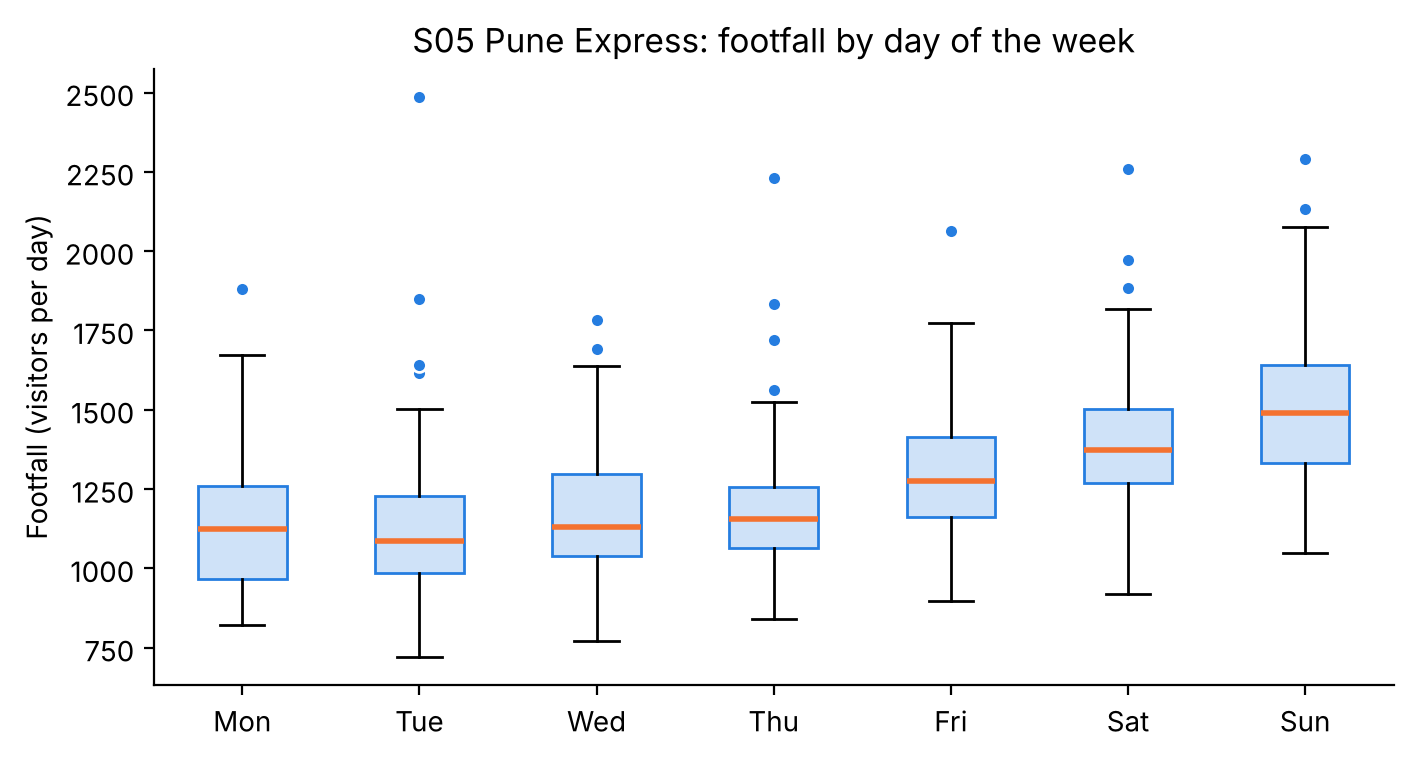

day_of_week
Monday       1125.0
Tuesday      1086.0
Wednesday    1132.0
Thursday     1155.5
Friday       1274.5
Saturday     1373.5
Sunday       1491.0


In [5]:
# Step 5. Side-by-side box plots: S05 footfall by day of the week
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
groups = [s05.loc[s05["day_of_week"] == d, "footfall"] for d in days]
plt.figure(figsize=(8, 4))
plt.boxplot(groups, **BOX)
plt.xticks(range(1, 8), [d[:3] for d in days])
plt.ylabel("Footfall (visitors per day)")
plt.title("S05 Pune Express: footfall by day of the week")
plt.show()
print(s05.groupby("day_of_week")["footfall"].median().reindex(days).rename("median").to_string())

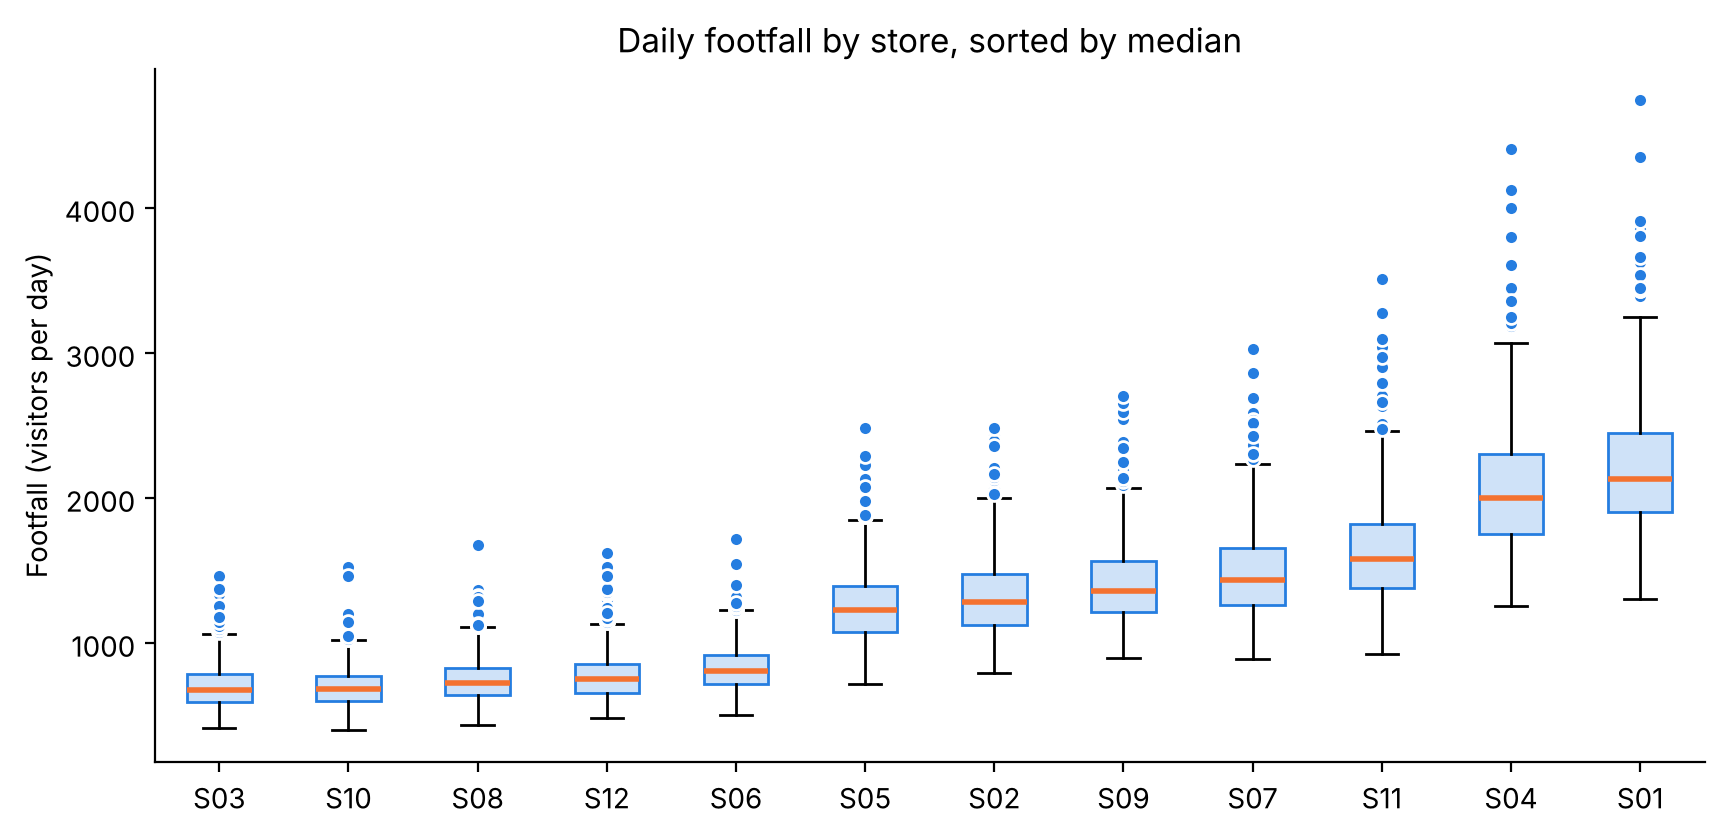

           25%   50%   75%  IQR
store_id                       
S03        595   674   785  189
S10        602   681   773  171
S08        642   724   831  189
S12        659   756   853  194
S06        715   808   921  205
S05       1077  1227  1393  316
S02       1128  1286  1477  349
S09       1213  1363  1563  350
S07       1264  1438  1658  394
S11       1383  1581  1819  436
S04       1755  2001  2302  547
S01       1907  2135  2451  544


In [6]:
# Step 6. Compare all 12 stores, sorted by median footfall
order = df.groupby("store_id")["footfall"].median().sort_values().index
groups = [df.loc[df["store_id"] == s, "footfall"] for s in order]
plt.figure(figsize=(10, 4.5))
plt.boxplot(groups, **BOX)
plt.xticks(range(1, 13), order)
plt.ylabel("Footfall (visitors per day)")
plt.title("Daily footfall by store, sorted by median")
plt.show()
summary = df.groupby("store_id")["footfall"].describe()[["25%", "50%", "75%"]].loc[order]
summary["IQR"] = summary["75%"] - summary["25%"]
print(summary.astype(int).to_string())

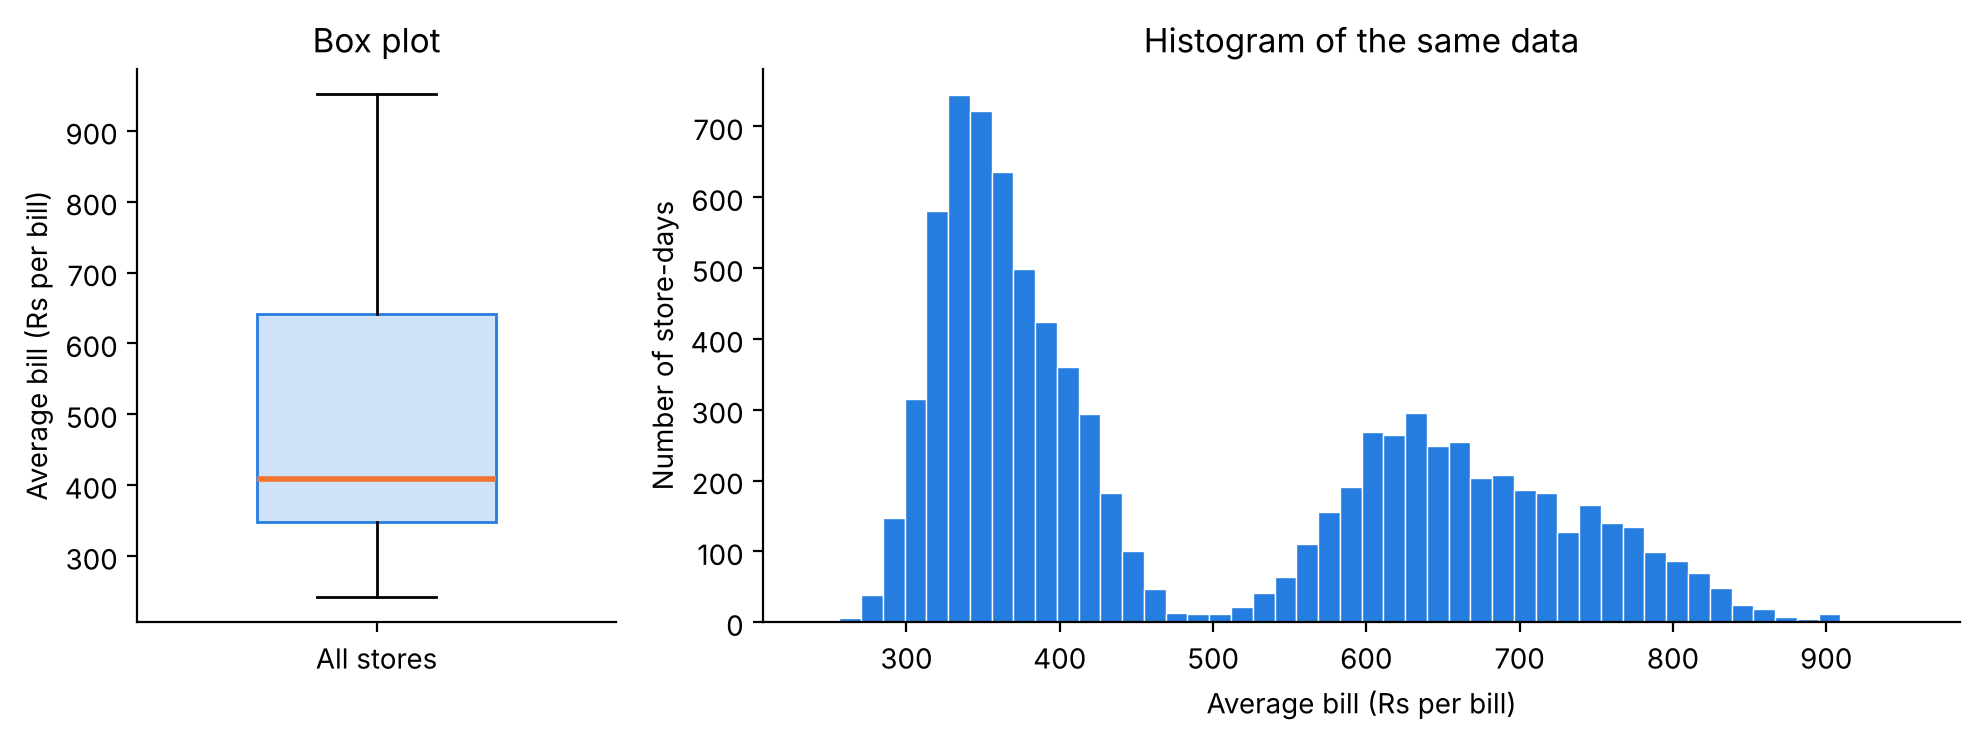

In [7]:
# Step 7. What a box plot cannot show: two humps in the average bill of all stores
bill = df["revenue_inr"] / df["transactions"]                 # rupees per bill
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 2.5]})
axes[0].boxplot(bill, widths=0.5, **BOX)
axes[0].set_xticks([1], ["All stores"])
axes[0].set_ylabel("Average bill (Rs per bill)")
axes[0].set_title("Box plot")
axes[1].hist(bill, bins=50, color="#257de0", edgecolor="white", linewidth=0.5)
axes[1].set_xlabel("Average bill (Rs per bill)")
axes[1].set_ylabel("Number of store-days")
axes[1].set_title("Histogram of the same data")
plt.tight_layout()
plt.show()